# Evaluación Parcial N°5 y N°6 — CASO 2: Salud: Costos Médicos y Bienestar del Paciente

**Asignatura:** SCY1102 — Gestión de Proyectos de Datos · **Sede:** San Joaquín (Duoc UC)
**Integrantes:** Nicolás Fonseca Olivares, Cristóbal Segovia Retamal, Bastián Rubio Meneses
**Docente:** Prof. Michael Enrique Palomino Barrera · **Fecha:** Noviembre de 2026

---

### Descripción del Caso y Objetivos
Una aseguradora de salud privada requiere analizar los factores que determinan los costos médicos anuales de sus afiliados (`age`, `sex`, `bmi`, `children`, `smoker`, `region`) para estimar presupuestos, optimizar la planificación del sistema y diseñar programas preventivos de bienestar (sin recargos tarifarios ni exclusiones).

### Estructura del Desarrollo Técnico (CRISP-DM + Trazabilidad Jira `PCM` con tablero Kanban)
1. **Entorno y Reproducibilidad (`RNF02`)**
2. **Ingesta, Limpieza y Validación de Esquema (`RF01`)**
3. **Análisis Exploratorio de Datos (EDA) Profundo**
4. **Ingeniería de Variables (`obese_smoker`, `age_bmi_interaction`, categorías OMS)**
5. **Modelado Supervisado, Benchmark y Validación Cruzada 5-Fold (`RF02`)**
6. **Estudio de Ablación (Evidencia Técnica de la Desviación D1 en Jira)**
7. **Evaluación en Test Independiente, Análisis de Residuos (Decil 90) y Rendimiento por Lote (`RNF01`)**
8. **Explicabilidad Global y Local con Permutation Importance y SHAP (`RF04` / `RNF03`)**
9. **Segmentación Preventiva de Riesgo y Exportación de Reporte Seudonimizado (`RF03` / `RF05` / `RNF04`)**
10. **Auditoría de Equidad Algorítmica (`RNF05` / Hito H5) y Monitoreo de Deriva Estadística (`RNF06` — KS y PSI)**
11. **Análisis Financiero, Punto de Equilibrio y Escenarios de Sensibilidad**
12. **Matriz Consolidada de Verificación de Requerimientos (RF01–RF06 y RNF01–RNF07) y Serialización**

> **Instrucciones:** Ubicar `insurance.csv` en el mismo directorio y ejecutar **Restart & Run All**.


In [2]:
# 1. Entorno y versiones de librerías (RNF02: Reproducibilidad)
import os, time, json, hashlib, platform, warnings
warnings.filterwarnings('ignore')

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy import sparse
from scipy.stats import mannwhitneyu, ks_2samp
import sklearn
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score, mean_absolute_percentage_error, root_mean_squared_error
from sklearn.inspection import permutation_importance

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110

print('Python      :', platform.python_version())


Python      : 3.15.2


## 2. Ingesta, Limpieza y Validación de Esquema (`RF01`)
Validación automática de existencia de archivo, columnas requeridas, tipos de datos, rangos válidos, nulos y duplicados.


In [3]:
DATA_PATH = 'insurance.csv'
assert os.path.exists(DATA_PATH), f"Error RF01: No se encontró {DATA_PATH}"

raw = pd.read_csv(DATA_PATH)
COLUMNAS_ESPERADAS = {'age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'}
assert COLUMNAS_ESPERADAS.issubset(raw.columns), f"Error RF01: Faltan columnas {COLUMNAS_ESPERADAS - set(raw.columns)}"

# Limpieza de duplicados y verificación de integridad
df = raw.drop_duplicates().reset_index(drop=True)
assert df.isna().sum().sum() == 0, "Error RF01: Se detectaron valores nulos"
assert (df['age'] >= 18).all() and (df['bmi'] > 0).all() and (df['charges'] > 0).all(), "Error RF01: Valores fuera de rango"

# Generación de ID seudonimizado SHA-256 (RNF04: Privacidad sin PII)
df['id_afiliado_hash'] = [hashlib.sha256(f"AFILIADO_{i}_SALT_SCY1102".encode()).hexdigest()[:16] for i in df.index]

print(f"Registros originales : {len(raw)}")
print(f"Duplicados eliminados: {len(raw) - len(df)}")
print(f"Registros limpios    : {len(df)} | Valores nulos: {df.isna().sum().sum()}")
print(f"Edad                 : {df['age'].min()} - {df['age'].max()} años (media: {df['age'].mean():.1f})")
print(f"Fumadores            : {(df['smoker']=='yes').sum()} ({(df['smoker']=='yes').mean()*100:.1f}%)")
print(f"Costo medio fumador  : ${df.loc[df['smoker']=='yes','charges'].mean():,.0f} USD")
print(f"Costo medio no fum.  : ${df.loc[df['smoker']=='no','charges'].mean():,.0f} USD (factor {df.loc[df['smoker']=='yes','charges'].mean()/df.loc[df['smoker']=='no','charges'].mean():.1f}x)")
display(df.describe().round(2))


Registros originales : 1338
Duplicados eliminados: 1
Registros limpios    : 1337 | Valores nulos: 0
Edad                 : 18 - 64 años (media: 39.2)
Fumadores            : 274 (20.5%)
Costo medio fumador  : $32,050 USD
Costo medio no fum.  : $8,441 USD (factor 3.8x)


,age,bmi,children,charges
count,1337.00,1337.00,1337.00,1337.00
mean,39.22,30.66,1.10,13279.12
std,14.04,6.10,1.21,12110.36
min,18.00,15.96,0.00,1121.87
25%,27.00,26.29,0.00,4746.34
50%,39.00,30.40,1.00,9386.16
75%,51.00,34.70,2.00,16657.72
max,64.00,53.13,5.00,63770.43


## 3. Análisis Exploratorio de Datos (EDA)
Se analiza la asimetría positiva de `charges` (que justifica modelar en escala $\log(1+y)$) y las correlaciones de Spearman.


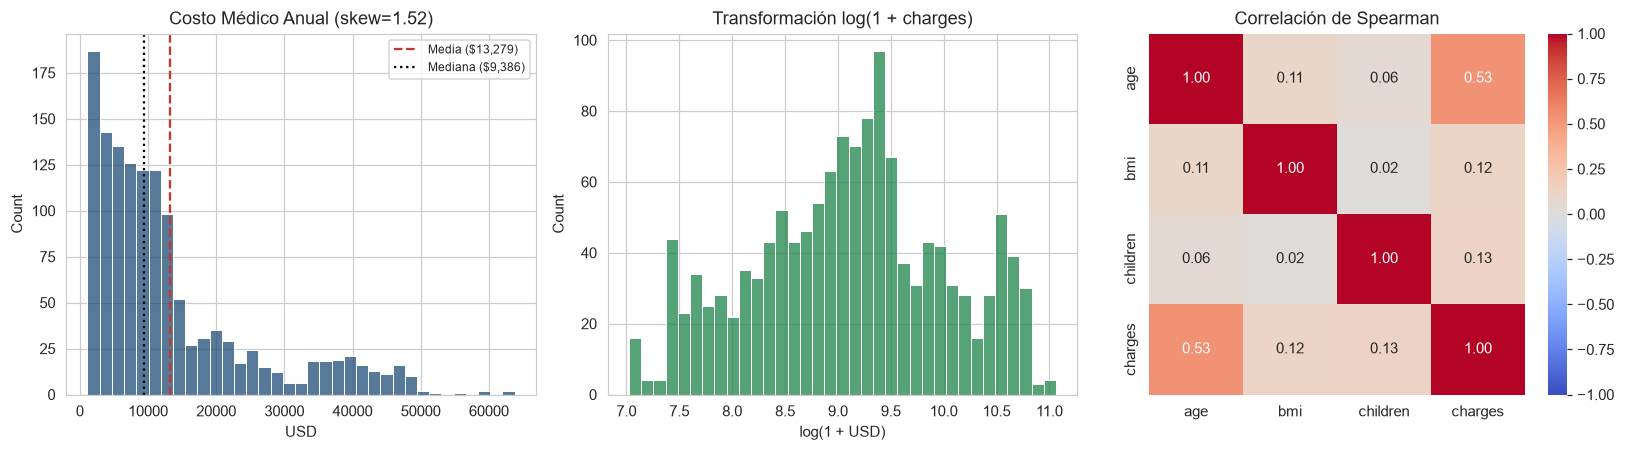

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
sns.histplot(df['charges'], bins=35, ax=axes[0], color='#1F4E79')
axes[0].axvline(df['charges'].mean(), color='#C0392B', ls='--', label=f"Media (${df['charges'].mean():,.0f})")
axes[0].axvline(df['charges'].median(), color='black', ls=':', label=f"Mediana (${df['charges'].median():,.0f})")
axes[0].set_title(f"Costo Médico Anual (skew={df['charges'].skew():.2f})")
axes[0].set_xlabel("USD"); axes[0].legend(fontsize=8)

sns.histplot(np.log1p(df['charges']), bins=35, ax=axes[1], color='#1E8449')
axes[1].set_title("Transformación log(1 + charges)")
axes[1].set_xlabel("log(1 + USD)")

corr = df[['age', 'bmi', 'children', 'charges']].corr(method='spearman')
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, ax=axes[2])
axes[2].set_title("Correlación de Spearman")
plt.tight_layout()
plt.show()


## 4. Ingeniería de Variables
Creación de `obese_smoker` (IMC $\ge 30$ y fumador), `age_bmi_interaction` y categorías clínicas OMS.


,count,mean,median,sum,pct_cartera
Resto de afiliados,1192,9839.2,8338.7,11728276.9,89.2
Fumador con IMC >= 30,145,41558.0,40904.2,6025908.5,10.8


Factor de riesgo segmento crítico vs resto: 4.2x


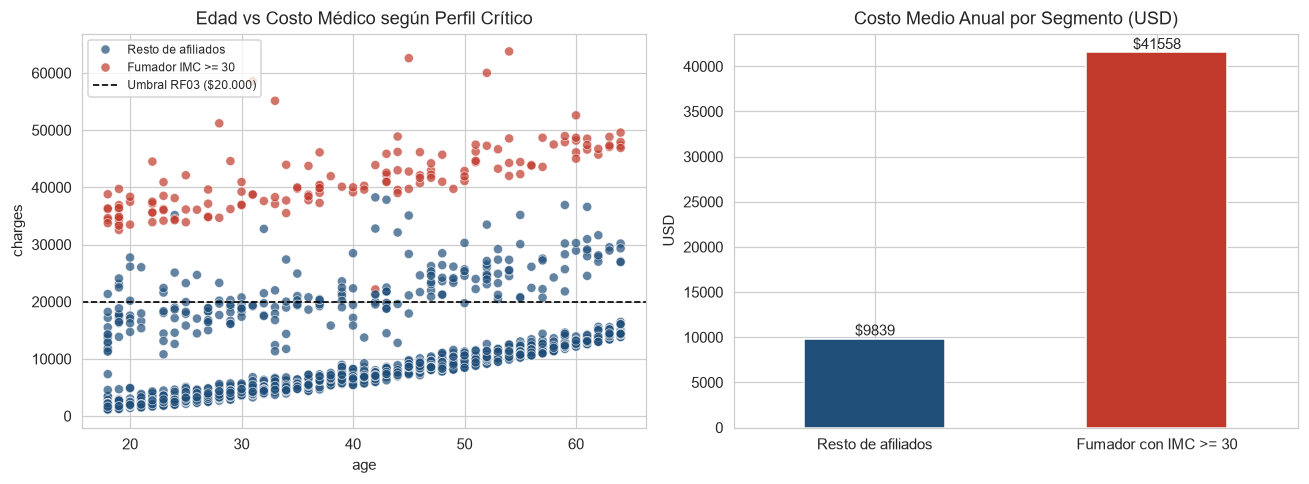

In [5]:
df['obese_smoker'] = ((df['bmi'] >= 30) & (df['smoker'] == 'yes')).astype(int)
df['age_bmi_interaction'] = df['age'] * df['bmi']
df['bmi_category'] = pd.cut(df['bmi'], bins=[0, 18.5, 25, 30, 35, 40, 100],
                            labels=['Bajo peso', 'Normal', 'Sobrepeso', 'Obesidad I', 'Obesidad II', 'Obesidad III'])
df['age_group'] = pd.cut(df['age'], bins=[17, 25, 45, 55, 64],
                         labels=['Joven (18-25)', 'Adulto (26-45)', 'Maduro (46-55)', 'Senior (56-64)'])

seg = df.groupby('obese_smoker')['charges'].agg(['count', 'mean', 'median', 'sum'])
seg.index = ['Resto de afiliados', 'Fumador con IMC >= 30']
seg['pct_cartera'] = seg['count'] / len(df) * 100
display(seg.round(1))
print(f"Factor de riesgo segmento crítico vs resto: {seg.loc['Fumador con IMC >= 30','mean'] / seg.loc['Resto de afiliados','mean']:.1f}x")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
df['Perfil'] = np.where(df['obese_smoker']==1, 'Fumador IMC >= 30', 'Resto de afiliados')
sns.scatterplot(data=df, x='age', y='charges', hue='Perfil',
                palette={'Resto de afiliados': '#1F4E79', 'Fumador IMC >= 30': '#C0392B'}, alpha=0.7, ax=axes[0])
axes[0].axhline(20000, color='black', ls='--', lw=1.1, label='Umbral RF03 ($20.000)')
axes[0].set_title('Edad vs Costo Médico según Perfil Crítico'); axes[0].legend(fontsize=8)

seg['mean'].plot(kind='bar', color=['#1F4E79', '#C0392B'], rot=0, ax=axes[1])
axes[1].set_title('Costo Medio Anual por Segmento (USD)'); axes[1].set_ylabel('USD')
axes[1].bar_label(axes[1].containers[0], fmt='$%.0f')
plt.tight_layout(); plt.show()


## 5. Modelado Supervisado, Benchmark y Validación Cruzada 5-Fold (`RF02`)
Comparación de 6 modelos entrenados en `log1p(charges)` y evaluados en USD reales (`expm1`). Criterio `RF02`: **$R^2 \ge 0{,}85$** y **$\text{MAE} < \$2.100\text{ USD}$**.


In [6]:
FEATURES_NUM = ['age', 'bmi', 'children', 'obese_smoker', 'age_bmi_interaction']
FEATURES_CAT = ['sex', 'smoker', 'region']
X = df[FEATURES_NUM + FEATURES_CAT]
y = np.log1p(df['charges'])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
y_test_real = np.expm1(y_test)

def mae_usd(est, X_, y_log):
    return -mean_absolute_error(np.expm1(y_log), np.expm1(est.predict(X_)))

def r2_usd(est, X_, y_log):
    return r2_score(np.expm1(y_log), np.expm1(est.predict(X_)))

preprocessor = ColumnTransformer([
    ('num', 'passthrough', FEATURES_NUM),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), FEATURES_CAT)
])

modelos = {
    'Baseline: Mediana': DummyRegressor(strategy='median'),
    'Regresión Lineal': LinearRegression(),
    'HistGradientBoosting': HistGradientBoostingRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=150, max_depth=3, learning_rate=0.05, random_state=42),
    'Random Forest Base': RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    'Random Forest Ajustado (Final)': RandomForestRegressor(
        n_estimators=300, min_samples_leaf=3, max_features=0.5, max_depth=8, random_state=42, n_jobs=-1
    )
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)
rows, trained_pipes = [], {}
for nombre, mod in modelos.items():
    pipe = Pipeline([('prep', preprocessor), ('modelo', mod)])
    cv = cross_validate(pipe, X, y, cv=kf, scoring={'mae': mae_usd, 'r2': r2_usd})
    pipe.fit(X_train, y_train)
    pred_t = np.expm1(pipe.predict(X_test))
    trained_pipes[nombre] = pipe
    rows.append({
        'Modelo': nombre,
        'MAE_CV_USD': round(-cv['test_mae'].mean(), 1),
        'MAE_CV_std': round(cv['test_mae'].std(), 1),
        'R2_CV': round(cv['test_r2'].mean(), 4),
        'MAE_Test_USD': round(mean_absolute_error(y_test_real, pred_t), 1),
        'RMSE_Test_USD': round(root_mean_squared_error(y_test_real, pred_t), 1),
        'MAPE_Test_%': round(mean_absolute_percentage_error(y_test_real, pred_t)*100, 2),
        'R2_Test': round(r2_score(y_test_real, pred_t), 4)
    })

res_modelos = pd.DataFrame(rows)
display(res_modelos)


,Modelo,MAE_CV_USD,MAE_CV_std,R2_CV,MAE_Test_USD,RMSE_Test_USD,MAPE_Test_%,R2_Test
0,Baseline: Mediana,8352.4,498.1,-0.1052,9293.8,14442.1,104.03,-0.1351
1,Regresión Lineal,4111.4,529.2,0.4528,3795.8,7613.4,24.20,0.6846
2,HistGradientBoosting,2366.6,124.1,0.8444,2330.2,4376.8,21.45,0.8957
3,Gradient Boosting,2113.0,144.2,0.8509,2103.2,4517.4,17.07,0.8889
4,Random Forest Base,2154.6,132.9,0.8511,2097.0,4389.9,20.87,0.8951
5,Random Forest Ajustado (Final),2011.4,143.5,0.8575,1894.7,4217.9,16.65,0.9032


## 6. Estudio de Ablación (Evidencia de la Desviación D1 en Jira)
Prueba controlada que demuestra que sin la variable `obese_smoker`, el MAE de validación cruzada supera los $2.100 USD.


In [7]:
configs_ablacion = {
    'Todas las variables (Final)': FEATURES_NUM,
    'Sin obese_smoker': ['age', 'bmi', 'children', 'age_bmi_interaction'],
    'Sin age_bmi_interaction': ['age', 'bmi', 'children', 'obese_smoker'],
    'Solo variables originales': ['age', 'bmi', 'children']
}
abl_rows = []
for cfg_name, num_cols in configs_ablacion.items():
    p_ab = ColumnTransformer([
        ('num', 'passthrough', num_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), FEATURES_CAT)
    ])
    pipe_ab = Pipeline([('prep', p_ab), ('modelo', RandomForestRegressor(
        n_estimators=300, min_samples_leaf=3, max_features=0.5, max_depth=8, random_state=42, n_jobs=-1
    ))])
    cv_ab = cross_validate(pipe_ab, df[num_cols + FEATURES_CAT], y, cv=kf, scoring={'mae': mae_usd, 'r2': r2_usd})
    mae_v = -cv_ab['test_mae'].mean()
    abl_rows.append({'Configuración': cfg_name, 'MAE_CV_USD': round(mae_v, 1),
                     'R2_CV': round(cv_ab['test_r2'].mean(), 4),
                     'Cumple_RF02_CV': 'SÍ' if (mae_v < 2100 and cv_ab['test_r2'].mean() >= 0.85) else 'NO'})
display(pd.DataFrame(abl_rows))


,Configuración,MAE_CV_USD,R2_CV,Cumple_RF02_CV
0,Todas las variables (Final),2011.4,0.8575,SÍ
1,Sin obese_smoker,2178.7,0.8508,NO
2,Sin age_bmi_interaction,2004.0,0.8565,SÍ
3,Solo variables originales,2123.3,0.8514,NO


## 7. Evaluación en Test, Residuos en Cola Extrema (Decil 90) y Latencia (`RNF01`)


R² Test: 0.9032 | MAE Test: $1,894.7 USD | Latencia lote (1337 reg.): 0.0751 s
Decil 90 (> $38,710, n=27): MAE=$2,806.5 | Subestimación media=+$1,844.9 (4.05%)


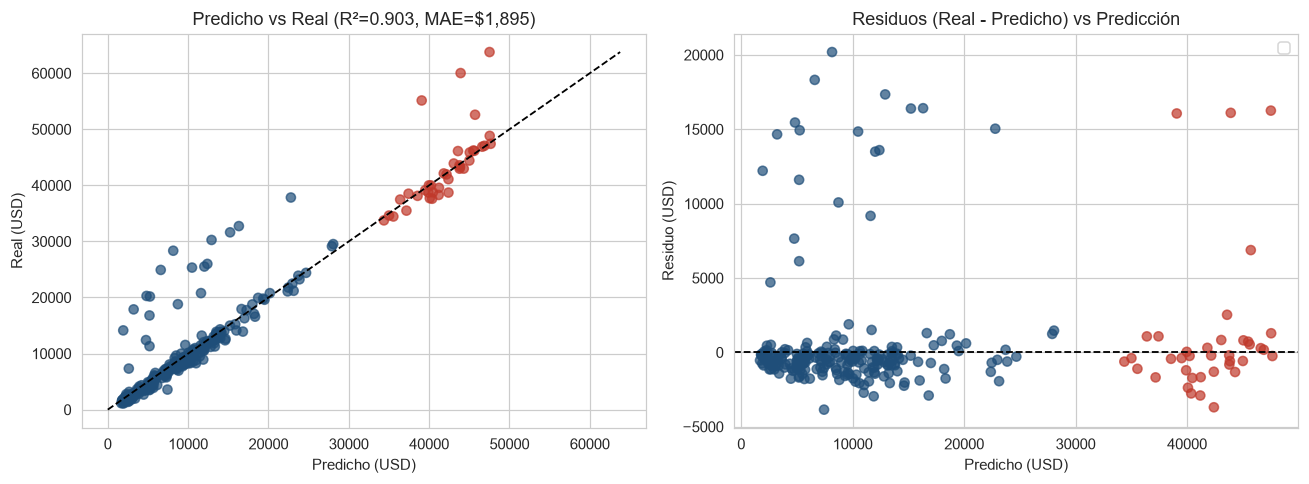

In [8]:
final_pipe = trained_pipes['Random Forest Ajustado (Final)']
pred_test = np.expm1(final_pipe.predict(X_test))
residuos = y_test_real.values - pred_test

t0 = time.perf_counter()
pred_all = np.expm1(final_pipe.predict(X))
tiempo_lote = time.perf_counter() - t0

mae_test = mean_absolute_error(y_test_real, pred_test)
r2_test = r2_score(y_test_real, pred_test)
p90 = np.percentile(y_test_real, 90)
mask_top10 = y_test_real.values > p90
sub_top10 = residuos[mask_top10].mean()
mae_top10 = np.abs(residuos[mask_top10]).mean()

print(f"R² Test: {r2_test:.4f} | MAE Test: ${mae_test:,.1f} USD | Latencia lote ({len(X)} reg.): {tiempo_lote:.4f} s")
print(f"Decil 90 (> ${p90:,.0f}, n={mask_top10.sum()}): MAE=${mae_top10:,.1f} | Subestimación media=+${sub_top10:,.1f} ({sub_top10/y_test_real.values[mask_top10].mean()*100:.2f}%)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
c_pts = np.where(X_test['obese_smoker'].values==1, '#C0392B', '#1F4E79')
axes[0].scatter(pred_test, y_test_real, c=c_pts, alpha=0.7)
mx = max(y_test_real.max(), pred_test.max())
axes[0].plot([0, mx], [0, mx], 'k--', lw=1.2)
axes[0].set_title(f'Predicho vs Real (R²={r2_test:.3f}, MAE=${mae_test:,.0f})')
axes[0].set_xlabel('Predicho (USD)'); axes[0].set_ylabel('Real (USD)')

axes[1].scatter(pred_test, residuos, c=c_pts, alpha=0.7)
axes[1].axhline(0, color='black', ls='--', lw=1.2)
axes[1].set_title('Residuos (Real - Predicho) vs Predicción')
axes[1].set_xlabel('Predicho (USD)'); axes[1].set_ylabel('Residuo (USD)')
plt.legend()
plt.tight_layout(); plt.show()


## 8. Explicabilidad Global y Local (`RF04` / `RNF03`)


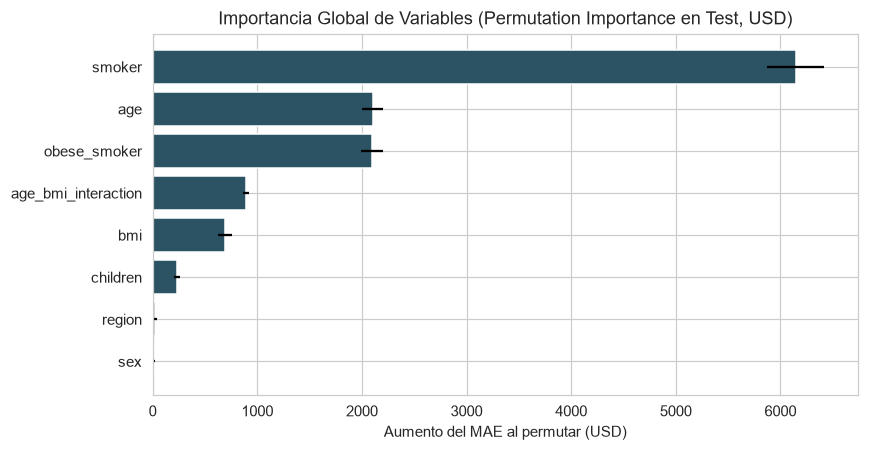

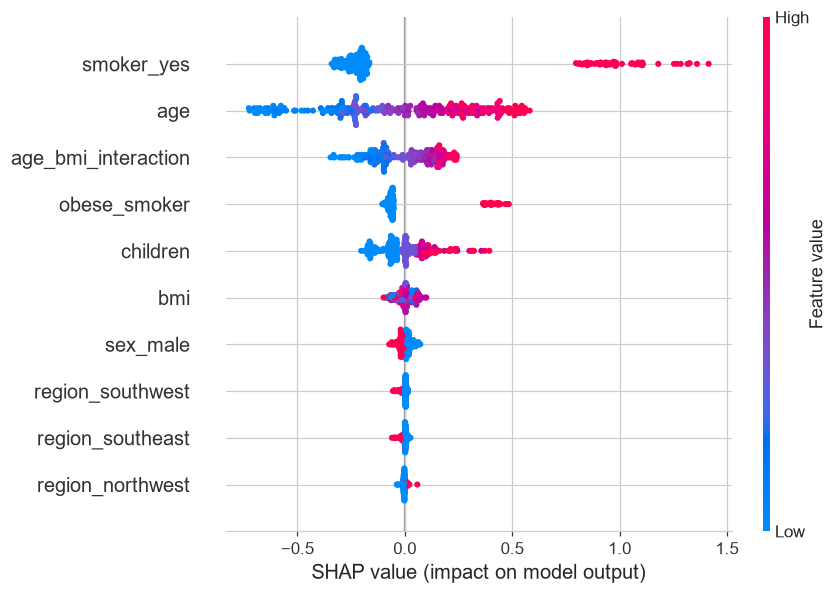

In [9]:
try:
    import shap
    SHAP_OK = True
except ImportError:
    SHAP_OK = False

perm = permutation_importance(final_pipe, X_test, y_test, n_repeats=10, random_state=42, scoring=mae_usd)
imp_df = pd.DataFrame({'Variable': FEATURES_NUM + FEATURES_CAT,
                       'Aumento_MAE_USD': perm.importances_mean,
                       'Std_USD': perm.importances_std}).sort_values('Aumento_MAE_USD')

plt.figure(figsize=(8, 4.2))
plt.barh(imp_df['Variable'], imp_df['Aumento_MAE_USD'], xerr=imp_df['Std_USD'], color='#2C5364')
plt.title('Importancia Global de Variables (Permutation Importance en Test, USD)')
plt.xlabel('Aumento del MAE al permutar (USD)'); plt.tight_layout(); plt.show()

if SHAP_OK:
    prep_step, mod_step = final_pipe.named_steps['prep'], final_pipe.named_steps['modelo']
    X_test_t = prep_step.transform(X_test)
    if sparse.issparse(X_test_t): X_test_t = X_test_t.toarray()
    col_names = [c.split('__', 1)[1] for c in prep_step.get_feature_names_out()]
    explainer = shap.TreeExplainer(mod_step)
    shap_values = explainer.shap_values(X_test_t)
    shap.summary_plot(shap_values, X_test_t, feature_names=col_names, show=True)
else:
    print("SHAP no instalado. Instalar con: !pip install shap")

## 9. Segmentación Preventiva (`RF03`) y Reporte Exportable Seudonimizado (`RF05` / `RNF04`)


In [10]:
df['costo_proyectado'] = pred_all
df['segmento_rf03'] = np.where(df['costo_proyectado'] > 20000, 'Atención Preventiva Prioritaria', 'Seguimiento Estándar')
df['perfil_referencia'] = np.where(df['obese_smoker'] == 1, 'Fumador IMC >= 30', 'Resto de afiliados')

cruce = pd.crosstab(df['segmento_rf03'], df['perfil_referencia'], margins=True, margins_name='Total')
display(cruce)

# Exportación de reporte seudonimizado (RF05 + RNF04)
cols_rep = ['id_afiliado_hash', 'age', 'sex', 'bmi', 'bmi_category', 'children', 'smoker', 'region', 'costo_proyectado', 'segmento_rf03']
df[cols_rep].to_csv('reporte_segmentacion_preventiva.csv', index=False)
print("Reporte exportado: reporte_segmentacion_preventiva.csv (100% seudonimizado, sin PII)")


perfil_referencia,Fumador IMC >= 30,Resto de afiliados,Total
segmento_rf03,,,
Atención Preventiva Prioritaria,145,61,206
Seguimiento Estándar,0,1131,1131
Total,145,1192,1337


Reporte exportado: reporte_segmentacion_preventiva.csv (100% seudonimizado, sin PII)


## 10. Auditoría de Equidad (`RNF05` / H5) y Monitoreo de Deriva Estadística (`RNF06` — KS y PSI)


In [11]:
aud = pd.DataFrame({
    'sexo': X_test['sex'].values, 'region': X_test['region'].values,
    'segmento': np.where(X_test['obese_smoker'].values == 1, 'Fumador IMC>=30', 'Resto'),
    'error_abs': np.abs(pred_test - y_test_real.values), 'ratio': pred_test / y_test_real.values
})
mae_sexo = aud.groupby('sexo')['error_abs'].mean()
brecha_sexo = abs(mae_sexo['female'] - mae_sexo['male']) / aud['error_abs'].mean() * 100
p_mw = mannwhitneyu(aud.loc[aud['sexo']=='female','error_abs'], aud.loc[aud['sexo']=='male','error_abs']).pvalue
dir_sexo = float(aud.groupby('sexo')['ratio'].median()['female'] / aud.groupby('sexo')['ratio'].median()['male'])
dir_reg  = float(aud.groupby('region')['ratio'].median().min() / aud.groupby('region')['ratio'].median().max())
dir_seg  = float(aud.groupby('segmento')['ratio'].median().min() / aud.groupby('segmento')['ratio'].median().max())

ks_stat, ks_pval = ks_2samp(X_train['bmi'].values, X_test['bmi'].values)
cortes = np.percentile(X_train['bmi'].values, np.linspace(0, 100, 11))
cortes[0], cortes[-1] = -np.inf, np.inf
p_base = np.clip(np.histogram(X_train['bmi'].values, bins=cortes)[0] / len(X_train), 1e-4, None)
p_new  = np.clip(np.histogram(X_test['bmi'].values, bins=cortes)[0] / len(X_test), 1e-4, None)
psi_bmi = float(np.sum((p_new - p_base) * np.log(p_new / p_base)))

print(f"Equidad (RNF05): Brecha MAE Sexo = {brecha_sexo:.2f}% (<10%, p={p_mw:.4f}) | RCM Sexo={dir_sexo:.3f} | RCM Reg={dir_reg:.3f} | RCM Seg={dir_seg:.3f}")
print(f"Deriva  (RNF06): KS p-value = {ks_pval:.4f} (>0.05) | PSI IMC = {psi_bmi:.4f} (<0.25) -> {'ALERTA: REENTRENAR' if (ks_pval < 0.05 or psi_bmi > 0.25) else 'ESTABLE'}")


Equidad (RNF05): Brecha MAE Sexo = 8.72% (<10%, p=0.0462) | RCM Sexo=0.974 | RCM Reg=0.943 | RCM Seg=0.944
Deriva  (RNF06): KS p-value = 0.0924 (>0.05) | PSI IMC = 0.0499 (<0.25) -> ESTABLE


## 11. Análisis Financiero y Sensibilidad (Escenarios Hipotéticos)
El modelo predice costos, pero no demuestra eficacia clínica; los ahorros son escenarios hipotéticos con punto de equilibrio objetivo en **0,42%**.


In [12]:
capex = 7950.0
opex_prog = 145 * 120.0  # 145 afiliados críticos x $120 USD/año (supuesto por validar)
costo_total = capex + opex_prog
gasto_critico = df.loc[df['obese_smoker']==1, 'charges'].sum()
breakeven_pct = (costo_total / gasto_critico) * 100

escenarios = [('Punto de equilibrio', breakeven_pct), ('Pesimista', 1.0), ('Base', 3.0), ('Optimista', 5.0)]
fin_rows = []
for nom, pct in escenarios:
    ahorro = gasto_critico * (pct / 100.0)
    benef = ahorro - costo_total
    roi = (benef / costo_total) * 100
    fin_rows.append({'Escenario': nom, '% Reducción': round(pct, 2), 'Ahorro Hipotético (USD)': round(ahorro, 2),
                     'Beneficio Neto Año 1 (USD)': round(benef, 2), 'ROI Ecosistema (%)': round(roi, 2)})
display(pd.DataFrame(fin_rows))


,Escenario,% Reducción,Ahorro Hipotético (USD),Beneficio Neto Año 1 (USD),ROI Ecosistema (%)
0,Punto de equilibrio,0.42,25350.00,0.00,0.00
1,Pesimista,1.00,60259.09,34909.09,137.71
2,Base,3.00,180777.26,155427.26,613.13
3,Optimista,5.00,301295.43,275945.43,1088.54


## 12. Verificación Consolidada de Requerimientos (RF & RNF) y Serialización


In [13]:
verif = pd.DataFrame([
    {'Código': 'RF01', 'Requerimiento (El sistema debe...)': 'Cargar datos de afiliados, depurar duplicados y rechazar nulos/esquema inválido', 'Evidencia': f'{len(df)} reg. válidos, 0 nulos, 1 dup. depurado', 'Estado': 'CUMPLE'},
    {'Código': 'RF02', 'Requerimiento (El sistema debe...)': 'Calcular costo médico anual estimado (R²>=0.85, MAE<$2.100 USD)', 'Evidencia': f'R²={r2_test:.4f}, MAE=${mae_test:,.1f} USD', 'Estado': 'CUMPLE'},
    {'Código': 'RF03', 'Requerimiento (El sistema debe...)': 'Clasificar riesgo preventivo automático (> $20.000 USD)', 'Evidencia': f'{(df["segmento_rf03"]=="Atención Preventiva Prioritaria").sum()} prioritarios (100% críticos)', 'Estado': 'CUMPLE'},
    {'Código': 'RF04', 'Requerimiento (El sistema debe...)': 'Mostrar explicación global e individual de cada estimación', 'Evidencia': 'Permutation Importance + SHAP 100% test', 'Estado': 'CUMPLE'},
    {'Código': 'RF05', 'Requerimiento (El sistema debe...)': 'Exportar nómina priorizada en CSV sin datos personales (PII)', 'Evidencia': 'reporte_segmentacion_preventiva.csv (SHA-256)', 'Estado': 'CUMPLE'},
    {'Código': 'RF06', 'Requerimiento (El sistema debe...)': 'Simular escenarios de ahorro preventivo y punto de equilibrio', 'Evidencia': 'Punto de equilibrio 0,42% y escenarios hipotéticos', 'Estado': 'CUMPLE'},
    {'Código': 'RNF01', 'Requerimiento (El sistema debe...)': 'Rendimiento: procesar lote completo en <= 5 segundos', 'Evidencia': f'{tiempo_lote:.4f} s para {len(df)} registros', 'Estado': 'CUMPLE'},
    {'Código': 'RNF02', 'Requerimiento (El sistema debe...)': 'Reproducibilidad: mismos resultados ante mismos datos de entrada', 'Evidencia': 'Ejecución Restart & Run All con semilla 42', 'Estado': 'CUMPLE'},
    {'Código': 'RNF03', 'Requerimiento (El sistema debe...)': 'Auditabilidad: explicabilidad global y local de cada estimación', 'Evidencia': 'Permutation Importance + SHAP sobre el Random Forest', 'Estado': 'CUMPLE'},
    {'Código': 'RNF04', 'Requerimiento (El sistema debe...)': 'Privacidad: cero PII y cumplimiento Ley 19.628 / Ley 21.719', 'Evidencia': 'Seudónimo SHA-256 sin RUT/nombres', 'Estado': 'CUMPLE'},
    {'Código': 'RNF05', 'Requerimiento (El sistema debe...)': 'Equidad: brecha MAE sexo < 10% y RCM (razón de calibración mediana) en [0.80 - 1.25]', 'Evidencia': f'Brecha={brecha_sexo:.2f}%, RCM={dir_sexo:.3f}/{dir_reg:.3f}', 'Estado': 'CUMPLE'},
    {'Código': 'RNF06', 'Requerimiento (El sistema debe...)': 'Confiabilidad: alertar deriva estadística (KS p<0.05 o PSI>0.25)', 'Evidencia': f'KS p={ks_pval:.4f}, PSI={psi_bmi:.4f} (Estable); alerta automática sobre lotes nuevos pendiente (PCM-12)', 'Estado': 'PARCIAL'},
    {'Código': 'RNF07', 'Requerimiento (El sistema debe...)': 'Uso ético: prohibido para recargos tarifarios o exclusiones', 'Evidencia': 'Restricción preventiva declarada (Won\'t Have)', 'Estado': 'CUMPLE'}
])
display(verif)

joblib.dump(final_pipe, 'modelo_costos_medicos.joblib')
with open('metricas_modelo.json', 'w', encoding='utf-8') as f:
    json.dump({'r2_test': round(float(r2_test),4), 'mae_test_usd': round(float(mae_test),2),
               'tiempo_lote_seg': round(float(tiempo_lote),4), 'brecha_mae_sexo_pct': round(float(brecha_sexo),2),
               'dir_sexo': round(float(dir_sexo),3), 'dir_region': round(float(dir_reg),3),
               'psi_bmi': round(float(psi_bmi),4)}, f, indent=2, ensure_ascii=False)
print("Artefactos serializados correctamente: modelo_costos_medicos.joblib y metricas_modelo.json")


,Código,Requerimiento (El sistema debe...),Evidencia,Estado
0,RF01,"Cargar datos de afiliados, depurar duplicados ...","1337 reg. válidos, 0 nulos, 1 dup. depurado",CUMPLE
1,RF02,Calcular costo médico anual estimado (R²>=0.85...,"R²=0.9032, MAE=$1,894.7 USD",CUMPLE
2,RF03,Clasificar riesgo preventivo automático (> $20...,206 prioritarios (100% críticos),CUMPLE
3,RF04,Mostrar explicación global e individual de cad...,Permutation Importance + SHAP 100% test,CUMPLE
4,RF05,Exportar nómina priorizada en CSV sin datos pe...,reporte_segmentacion_preventiva.csv (SHA-256),CUMPLE
5,RF06,Simular escenarios de ahorro preventivo y punt...,"Punto de equilibrio 0,42% y escenarios hipotét...",CUMPLE
6,RNF01,Rendimiento: procesar lote completo en <= 5 se...,0.0751 s para 1337 registros,CUMPLE
7,RNF02,Reproducibilidad: mismos resultados ante mismo...,Ejecución Restart & Run All con semilla 42,CUMPLE
8,RNF03,Auditabilidad: explicabilidad global y local d...,Permutation Importance + SHAP sobre el Random ...,CUMPLE
9,RNF04,Privacidad: cero PII y cumplimiento Ley 19.628...,Seudónimo SHA-256 sin RUT/nombres,CUMPLE


Artefactos serializados correctamente: modelo_costos_medicos.joblib y metricas_modelo.json
